# Monitores, sondas y puntos de control

**FEM-sim · cuaderno de ejemplo**

Un cálculo largo no debería ser una caja negra. Este cuaderno muestra, sobre un problema pequeño, cómo **ver lo que ocurre mientras se resuelve** y cómo **no perderlo si se interrumpe**:

1. **Monitor de iteraciones** (`on_iteration`): la tabla de convergencia del Newton, y detener el cálculo desde fuera.
2. **Sondas** (`addProbe`): el valor de un campo en un punto a lo largo del cálculo.
3. **Monitor de pasos** (`on_step`): reaccionar a cada paso de tiempo, por ejemplo parar al alcanzar un valor.
4. **Puntos de control** (`checkpoint` / `resume`): guardar el estado del transitorio y continuar después, con el mismo resultado que un cálculo sin interrupciones.

El problema: una placa cuadrada de lado 1 con una fuente de calor uniforme, bordes a temperatura cero y una conductividad que crece con la temperatura, $k(T) = 1 + 0.3\,T$. Es no lineal, así que hay iteraciones de Newton que mirar.

In [1]:
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt

from femsim.Pre_processing.Mesh import Mesh
from femsim.core import Model
from femsim.Material import material
from femsim.Physics.HeatTransfer import ht
from femsim.enums import ElementType


def placa():
    malla = Mesh()
    malla.generate2DMesh((1.0, 1.0), (16, 16), ElementType.quadrilateral)
    modelo = Model(name='placa', dim=2, mesh=malla, mat=material('X', k=1.0, rho=1.0, Cp=1.0), psc=ht)
    modelo.physics.Convection = False
    modelo.physics.F_const = 10.0                                   # fuente de calor uniforme
    modelo.physics.setConductivityLaw(lambda T: 1.0 + 0.3 * T)      # k(T): problema no lineal
    modelo.physics.addBC_TemperatureEdges(malla.boundary_edges(), 0.0)
    modelo.physics.initField('T', 0.0)
    return modelo

## 1. Monitor de iteraciones y tabla de convergencia

`model.solve(on_iteration=f)` llama a `f(info)` en cada iteración de Newton. `info` trae el número de iteración (`iteration`), el residuo escalado (`residual`), el residuo relativo al inicial (`relative_residual`) y el estado completo (`x`, solo para leer).

Al terminar, `model.convergence` guarda la misma tabla, una fila por iteración.

In [2]:
modelo = placa()
modelo.solve(on_iteration=lambda info: print(f"iteración {info['iteration']}: residuo relativo {info['relative_residual']:.2e}"))

print()
print("Tabla guardada:", [f"{fila['relative_residual']:.1e}" for fila in modelo.convergence])

2026-11-15 12:13:17 - INFO - ------- Starting simulation -------
2026-11-15 12:13:17 - INFO - Model: placa
2026-11-15 12:13:17 - INFO - Dimension: 2D
2026-11-15 12:13:17 - INFO - Nodes: 289
2026-11-15 12:13:17 - INFO - Elements: 256
2026-11-15 12:13:17 - INFO - Physics: Heat transfer
2026-11-15 12:13:17 - INFO - ------- Solver configuration -------
2026-11-15 12:13:17 - INFO - Study: Steady state
2026-11-15 12:13:17 - INFO - Type: Nonlinear
2026-11-15 12:13:17 - INFO - Method: Auto
2026-11-15 12:13:17 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:13:17 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-15 12:13:17 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-15 12:13:17 - INFO - -----------------------------------------------------------
2026-11-15 12:13:17 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11-15 12:13:17 - INFO - --------------------------

iteración 1: residuo relativo 1.13e-01
iteración 2: residuo relativo 1.05e-03
iteración 3: residuo relativo 8.88e-08
iteración 4: residuo relativo 2.49e-15

Tabla guardada: ['1.1e-01', '1.1e-03', '8.9e-08', '2.5e-15']


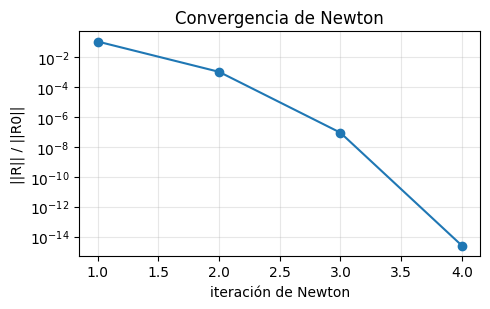

In [3]:
iteraciones = [fila['iteration'] for fila in modelo.convergence]
relativo = [fila['relative_residual'] for fila in modelo.convergence]

plt.figure(figsize=(5, 3.2))
plt.semilogy(iteraciones, relativo, 'o-')
plt.xlabel('iteración de Newton'); plt.ylabel('||R|| / ||R0||'); plt.title('Convergencia de Newton')
plt.grid(True, which='both', alpha=0.3); plt.tight_layout(); plt.show()

**Detener desde fuera.** Si el monitor devuelve `True`, el cálculo se para y conserva el estado alcanzado. Aquí se corta tras la primera iteración; `nonlinear_converged` queda en `False` porque el residuo todavía no bajó de la tolerancia.

In [4]:
cortado = placa()
cortado.solve(on_iteration=lambda info: info['iteration'] >= 1)
print("Iteraciones hechas:", cortado.newton_iterations, "| convergió:", cortado.nonlinear_converged)

2026-11-15 12:14:10 - INFO - ------- Starting simulation -------
2026-11-15 12:14:11 - INFO - Model: placa
2026-11-15 12:14:11 - INFO - Dimension: 2D
2026-11-15 12:14:11 - INFO - Nodes: 289
2026-11-15 12:14:11 - INFO - Elements: 256
2026-11-15 12:14:11 - INFO - Physics: Heat transfer
2026-11-15 12:14:11 - INFO - ------- Solver configuration -------
2026-11-15 12:14:11 - INFO - Study: Steady state
2026-11-15 12:14:11 - INFO - Type: Nonlinear
2026-11-15 12:14:11 - INFO - Method: Auto
2026-11-15 12:14:11 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:14:11 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-15 12:14:11 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-15 12:14:11 - INFO - -----------------------------------------------------------
2026-11-15 12:14:11 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11-15 12:14:11 - INFO - --------------------------

Iteraciones hechas: 1 | convergió: False


## 2. Sondas

`addProbe(nombre, campo, point=(x, y))` registra el campo en el nodo más cercano a ese punto (también se puede dar `node=` con el índice, y `component=` para un campo vectorial). En un estudio transitorio se muestrea en t = 0 y después de cada paso; en uno estacionario, en cada iteración.

Primero, el valor estacionario en el centro, que usaremos como referencia más abajo.

In [5]:
referencia = placa()
referencia.addProbe('centro', 'T', point=(0.5, 0.5))
referencia.solve()
T_estacionaria = referencia.probe_values['centro'][-1]
print(f"Temperatura estacionaria en el centro: {T_estacionaria:.4f}")

2026-11-15 12:14:41 - INFO - ------- Starting simulation -------
2026-11-15 12:14:41 - INFO - Model: placa
2026-11-15 12:14:41 - INFO - Dimension: 2D
2026-11-15 12:14:41 - INFO - Nodes: 289
2026-11-15 12:14:41 - INFO - Elements: 256
2026-11-15 12:14:41 - INFO - Physics: Heat transfer
2026-11-15 12:14:41 - INFO - ------- Solver configuration -------
2026-11-15 12:14:41 - INFO - Study: Steady state
2026-11-15 12:14:41 - INFO - Type: Nonlinear
2026-11-15 12:14:41 - INFO - Method: Auto
2026-11-15 12:14:41 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:14:41 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-15 12:14:41 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-15 12:14:41 - INFO - -----------------------------------------------------------
2026-11-15 12:14:41 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11-15 12:14:41 - INFO - --------------------------

Temperatura estacionaria en el centro: 0.6715


Ahora el transitorio (BDF2, 20 pasos de 0.02) con dos sondas: el centro y un punto cercano al borde.

2026-11-15 12:14:51 - INFO - ------- Starting simulation -------
2026-11-15 12:14:51 - INFO - Model: placa
2026-11-15 12:14:51 - INFO - Dimension: 2D
2026-11-15 12:14:51 - INFO - Nodes: 289
2026-11-15 12:14:51 - INFO - Elements: 256
2026-11-15 12:14:51 - INFO - Physics: Heat transfer
2026-11-15 12:14:51 - INFO - ------- Solver configuration -------
2026-11-15 12:14:51 - INFO - Study: Transient
2026-11-15 12:14:51 - INFO - Type: Nonlinear
2026-11-15 12:14:51 - INFO - Method: Direct
2026-11-15 12:14:51 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:14:51 - INFO - Time Discretization: 1, scheme: BDF2
2026-11-15 12:14:51 - INFO - Time Step: 0.02
2026-11-15 12:14:51 - INFO - Total Time: 0.4
2026-11-15 12:14:52 - INFO - Theta = 1.0, scheme = BDF2, steps = 20, dt = 0.02
2026-11-15 12:14:52 - INFO - Paso 2/20 (t = 0.04, 10 %): 0.5 s transcurridos, ~4.7 s restantes
2026-11-15 12:14:52 - INFO - Paso 4/20 (t = 0.08, 20 %): 0.5 s transcurridos, ~2.1 s restantes
2026-11-15 1

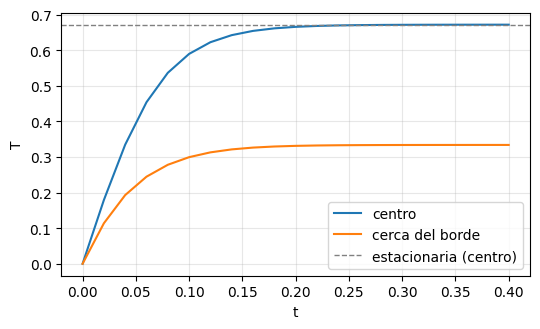

Diferencia con la historia guardada: 0.0


In [6]:
def transitorio(total=0.4):
    modelo = placa()
    modelo.solverConfiguration(Study='transient', timeScheme='BDF2', timeStep=0.02, totalTime=total)
    modelo.addProbe('centro', 'T', point=(0.5, 0.5))
    modelo.addProbe('cerca del borde', 'T', point=(0.1, 0.5))
    return modelo

completo = transitorio()
completo.solve()

plt.figure(figsize=(5.5, 3.4))
for nombre, valores in completo.probe_values.items():
    plt.plot(completo.probe_times, valores, label=nombre)
plt.axhline(T_estacionaria, color='gray', ls='--', lw=1, label='estacionaria (centro)')
plt.xlabel('t'); plt.ylabel('T'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# la sonda es el mismo nodo de la historia guardada
nodo = completo.probes['centro']['node']
print("Diferencia con la historia guardada:", np.max(np.abs(np.array(completo.probe_values['centro']) - np.asarray(completo.sol['T'])[nodo, :])))

## 3. Monitor de pasos

`on_step(info)` se llama tras cada paso aceptado: `info['step']`, `info['time']`, `info['dt']`, `info['newton_iterations']` y el estado `info['x']`. Como los demás monitores, detiene el cálculo si devuelve `True`.

Ejemplo: parar cuando el centro llega al 95 % de la temperatura estacionaria.

In [7]:
dof_centro = completo.layout.dofs('T')[nodo, 0]

def al_95_por_ciento(info):
    T_centro = info['x'][dof_centro]
    print(f"paso {info['step']:2d}  t = {info['time']:.2f}  T_centro = {T_centro:.3f}  (Newton: {info['newton_iterations']} it.)")
    return T_centro >= 0.95 * T_estacionaria

parado = transitorio()
parado.solve(on_step=al_95_por_ciento)
print(f"\nParado en t = {parado.timeVector[-1]:.2f} de 0.4; pasos guardados: {len(parado.timeVector) - 1}")

2026-11-15 12:15:44 - INFO - ------- Starting simulation -------
2026-11-15 12:15:44 - INFO - Model: placa
2026-11-15 12:15:44 - INFO - Dimension: 2D
2026-11-15 12:15:44 - INFO - Nodes: 289
2026-11-15 12:15:44 - INFO - Elements: 256
2026-11-15 12:15:44 - INFO - Physics: Heat transfer
2026-11-15 12:15:44 - INFO - ------- Solver configuration -------
2026-11-15 12:15:44 - INFO - Study: Transient
2026-11-15 12:15:44 - INFO - Type: Nonlinear
2026-11-15 12:15:44 - INFO - Method: Direct
2026-11-15 12:15:44 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:15:44 - INFO - Time Discretization: 1, scheme: BDF2
2026-11-15 12:15:44 - INFO - Time Step: 0.02
2026-11-15 12:15:44 - INFO - Total Time: 0.4
2026-11-15 12:15:44 - INFO - Theta = 1.0, scheme = BDF2, steps = 20, dt = 0.02
2026-11-15 12:15:45 - INFO - Paso 2/20 (t = 0.04, 10 %): 0.5 s transcurridos, ~4.4 s restantes
2026-11-15 12:15:45 - INFO - Paso 4/20 (t = 0.08, 20 %): 0.5 s transcurridos, ~2.0 s restantes
2026-11-15 1

paso  1  t = 0.02  T_centro = 0.179  (Newton: 5 it.)
paso  2  t = 0.04  T_centro = 0.335  (Newton: 4 it.)
paso  3  t = 0.06  T_centro = 0.454  (Newton: 4 it.)
paso  4  t = 0.08  T_centro = 0.536  (Newton: 5 it.)
paso  5  t = 0.10  T_centro = 0.589  (Newton: 6 it.)
paso  6  t = 0.12  T_centro = 0.622  (Newton: 6 it.)
paso  7  t = 0.14  T_centro = 0.642  (Newton: 6 it.)

Parado en t = 0.14 de 0.4; pasos guardados: 7


La tabla por paso queda en `parado.convergence` (paso, tiempo, `dt`, iteraciones de Newton).

In [8]:
print(parado.convergence[-1])

{'kind': 'step', 'step': 7, 'time': 0.14, 'dt': 0.02, 'newton_iterations': 6}


## 4. Puntos de control y reanudación

`checkpoint='archivo.npz'` guarda cada 10 pasos (o `('archivo', 5)` para cada 5) todo lo que el bucle de tiempo necesita: historia, estado, paso, `dt`, tamaños para el control adaptativo y las sondas ya registradas. El archivo se reescribe de forma atómica, así que una caída durante el guardado no lo corrompe. Al detener el cálculo con un monitor también se guarda.

`resume='archivo.npz'` continúa desde ahí. Se comprueba que el caso es el mismo (esquema, tiempo total, número de incógnitas); si no, da un error claro en vez de un resultado equivocado.

Simulamos una interrupción en el paso 12 de 20.

In [9]:
carpeta = tempfile.mkdtemp()
archivo = os.path.join(carpeta, 'placa.npz')

# Primera ejecución: guarda cada 5 pasos y se "interrumpe" en el paso 12
primera = transitorio()
primera.solve(checkpoint=(archivo, 5), on_step=lambda info: info['step'] == 12)
print("Tiempo alcanzado:", round(primera.timeVector[-1], 2), "| archivo:", os.path.basename(archivo), os.path.getsize(archivo), "bytes")

2026-11-15 12:16:53 - INFO - ------- Starting simulation -------
2026-11-15 12:16:53 - INFO - Model: placa
2026-11-15 12:16:53 - INFO - Dimension: 2D
2026-11-15 12:16:53 - INFO - Nodes: 289
2026-11-15 12:16:53 - INFO - Elements: 256
2026-11-15 12:16:53 - INFO - Physics: Heat transfer
2026-11-15 12:16:53 - INFO - ------- Solver configuration -------
2026-11-15 12:16:53 - INFO - Study: Transient
2026-11-15 12:16:53 - INFO - Type: Nonlinear
2026-11-15 12:16:53 - INFO - Method: Direct
2026-11-15 12:16:53 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:16:53 - INFO - Time Discretization: 1, scheme: BDF2
2026-11-15 12:16:53 - INFO - Time Step: 0.02
2026-11-15 12:16:53 - INFO - Total Time: 0.4
2026-11-15 12:16:53 - INFO - Theta = 1.0, scheme = BDF2, steps = 20, dt = 0.02
2026-11-15 12:16:53 - INFO - Paso 2/20 (t = 0.04, 10 %): 0.4 s transcurridos, ~3.7 s restantes
2026-11-15 12:16:53 - INFO - Paso 4/20 (t = 0.08, 20 %): 0.4 s transcurridos, ~1.7 s restantes
2026-11-15 1

Tiempo alcanzado: 0.24 | archivo: placa.npz 40296 bytes


In [10]:
# Segunda ejecución, con el mismo caso: continúa desde el punto de control
segunda = transitorio()
segunda.solve(resume=archivo)

# Comparación con un cálculo sin interrupciones
diferencia = np.max(np.abs(np.asarray(segunda.sol['T']) - np.asarray(completo.sol['T'])))
print("Pasos:", len(segunda.timeVector) - 1, "| diferencia máxima con el cálculo continuo:", f"{diferencia:.1e}")
print("Sonda del centro restaurada, muestras:", len(segunda.probe_values['centro']))

2026-11-15 12:17:26 - INFO - ------- Starting simulation -------
2026-11-15 12:17:26 - INFO - Model: placa
2026-11-15 12:17:26 - INFO - Dimension: 2D
2026-11-15 12:17:26 - INFO - Nodes: 289
2026-11-15 12:17:26 - INFO - Elements: 256
2026-11-15 12:17:26 - INFO - Physics: Heat transfer
2026-11-15 12:17:26 - INFO - ------- Solver configuration -------
2026-11-15 12:17:26 - INFO - Study: Transient
2026-11-15 12:17:26 - INFO - Type: Nonlinear
2026-11-15 12:17:26 - INFO - Method: Direct
2026-11-15 12:17:26 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:17:26 - INFO - Time Discretization: 1, scheme: BDF2
2026-11-15 12:17:26 - INFO - Time Step: 0.02
2026-11-15 12:17:26 - INFO - Total Time: 0.4
2026-11-15 12:17:26 - INFO - Theta = 1.0, scheme = BDF2, steps = 20, dt = 0.02
2026-11-15 12:17:26 - INFO - Reanudando desde C:\Users\ALEJAN~1\AppData\Local\Temp\tmpx4sc55pr\placa.npz (paso 12, t = 0.24).
2026-11-15 12:17:26 - INFO - Paso 14/20 (t = 0.28, 70 %): 0.4 s transcurrido

Pasos: 20 | diferencia máxima con el cálculo continuo: 6.1e-11
Sonda del centro restaurada, muestras: 21


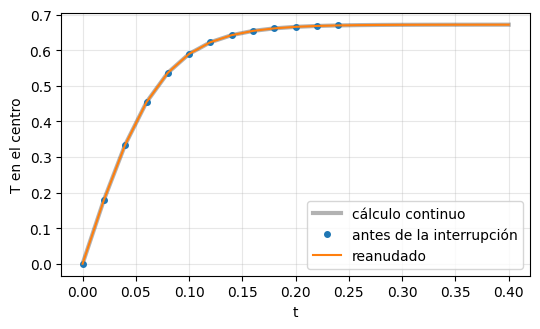

In [11]:
plt.figure(figsize=(5.5, 3.4))
plt.plot(completo.probe_times, completo.probe_values['centro'], 'k-', lw=3, alpha=0.3, label='cálculo continuo')
plt.plot(primera.probe_times, primera.probe_values['centro'], 'o', ms=4, label='antes de la interrupción')
plt.plot(segunda.probe_times, segunda.probe_values['centro'], '-', label='reanudado')
plt.xlabel('t'); plt.ylabel('T en el centro'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Una configuración distinta se rechaza.** Si se intenta reanudar con otro tiempo total, el modelo avisa en lugar de mezclar dos casos.

In [12]:
otro = transitorio(total=0.8)
try:
    otro.solve(resume=archivo)
except ValueError as error:
    print("Rechazado:", error)

2026-11-15 12:17:51 - INFO - ------- Starting simulation -------
2026-11-15 12:17:51 - INFO - Model: placa
2026-11-15 12:17:51 - INFO - Dimension: 2D
2026-11-15 12:17:51 - INFO - Nodes: 289
2026-11-15 12:17:51 - INFO - Elements: 256
2026-11-15 12:17:51 - INFO - Physics: Heat transfer
2026-11-15 12:17:51 - INFO - ------- Solver configuration -------
2026-11-15 12:17:51 - INFO - Study: Transient
2026-11-15 12:17:51 - INFO - Type: Nonlinear
2026-11-15 12:17:51 - INFO - Method: Direct
2026-11-15 12:17:51 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-15 12:17:51 - INFO - Time Discretization: 1, scheme: BDF2
2026-11-15 12:17:51 - INFO - Time Step: 0.02
2026-11-15 12:17:51 - INFO - Total Time: 0.8
2026-11-15 12:17:51 - INFO - Theta = 1.0, scheme = BDF2, steps = 40, dt = 0.02


Rechazado: Punto de control 'C:\\Users\\ALEJAN~1\\AppData\\Local\\Temp\\tmpx4sc55pr\\placa.npz': total_time = 0.4, la configuracion actual tiene 0.8.


## Resumen

| Quiero... | Uso |
|---|---|
| Ver cómo converge Newton | `solve(on_iteration=f)` y `model.convergence` |
| Seguir un valor en un punto | `addProbe(nombre, campo, point=...)`, `probe_times`, `probe_values` |
| Reaccionar a cada paso o parar el cálculo | `solve(on_step=g)`; devolver `True` detiene |
| No perder un transitorio largo | `solve(checkpoint='caso.npz')` y después `solve(resume='caso.npz')` |

Notas: el resultado reanudado coincide con el continuo a la tolerancia del Newton, no bit a bit, porque tras reanudar se reconstruye la tangente. Los solvers lineales iterativos (Krylov) no tienen monitor propio; los monitores actúan sobre las iteraciones no lineales y los pasos de tiempo.